# **Risk Model Regressions**

This notebook processes 43 stocks over 80 dated four-week return observations.  
\
It estimates   
(1) designated foreign-currency exposure,    
(2) AUD exposure for every stock, and   
(3) sector-factor exposure using iterative backward elimination.

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd().parent  # group4

DATA = ROOT / "data"
RAW = DATA / "raw"
PROCESSED = DATA / "processed"

OUT = ROOT / "results"
COEFF = OUT / "coefficients"
RESID = OUT / "residuals"
DIAG = OUT / "diagnostics"

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [2]:
for folder in ["raw", "processed"]:
    path = DATA / folder

    print(f"\n{folder.upper()} DATA:")

    if path.exists():
        for file in sorted(path.glob("*.xlsx")):
            print(f"  {file.name}")
    else:
        print(f"Folder not found: {path.resolve()}")


RAW DATA:
  raw_4w_endpoint_prices.xlsx
  raw_4w_log_returns.xlsx

PROCESSED DATA:
  australian_dollar.xlsx
  equities_logret_4w_pre_sector.xlsx
  equities_logret_4w_timeweighted_43stocks.xlsx
  gics11_sector_logret_4w_spy_resid.xlsx
  universe_logret_4w_timeweighted_all.xlsx


### **Data Setup**

In [3]:
# Time-weighted 4-week returns
df_universe = pd.read_excel(
    PROCESSED / "universe_logret_4w_timeweighted_all.xlsx",
    index_col=0
)

df_stocks = pd.read_excel(
    PROCESSED / "equities_logret_4w_timeweighted_43stocks.xlsx",
    index_col=0
)

# Australian dollar 
df_aud = pd.read_excel(
    PROCESSED / "australian_dollar.xlsx",
    index_col=0
)

# Sector residual returns (market effect removed)
df_sectors = pd.read_excel(
    PROCESSED / "gics11_sector_logret_4w_spy_resid.xlsx",
    index_col=0
)

In [4]:
datasets = {
    "Universe": df_universe,
    "Stocks": df_stocks,
    "AUD": df_aud,
    "Sectors": df_sectors
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Columns:", df.columns.tolist())


Universe
Shape: (80, 61)
Missing values: 15
Columns: ['VST', 'VIST', 'AEP', 'ETR', 'DIS', 'CMG', 'AMZN', 'FIX', 'STX', 'VLO', 'CF', 'NTR', 'LNN', 'WDC', 'ASND', 'DOCN', 'CME', 'NET', 'MRNA', 'AXON', 'NFLX', 'CMCSA', 'MU', 'NEM', 'PGR', 'ORKA', 'UPST', 'PG', 'F', 'HPE', 'BA', 'HII', 'AMD', 'LLY', 'WELL', 'NOK', 'MSFT', 'GOOGL', 'COST', 'HD', 'KO', 'JNJ', 'BRK-B', 'SPY', 'XLC', 'XLY', 'XLP', 'XLE', 'XLF', 'XLV', 'XLI', 'XLB', 'XLRE', 'XLK', 'XLU', 'MXN/USD', 'SGD/USD', 'DKK/USD', 'EUR/USD', 'AUD/USD', 'CAD/USD']

Stocks
Shape: (80, 43)
Missing values: 15
Columns: ['VST', 'VIST', 'AEP', 'ETR', 'DIS', 'CMG', 'AMZN', 'FIX', 'STX', 'VLO', 'CF', 'NTR', 'LNN', 'WDC', 'ASND', 'DOCN', 'CME', 'NET', 'MRNA', 'AXON', 'NFLX', 'CMCSA', 'MU', 'NEM', 'PGR', 'ORKA', 'UPST', 'PG', 'F', 'HPE', 'BA', 'HII', 'AMD', 'LLY', 'WELL', 'NOK', 'MSFT', 'GOOGL', 'COST', 'HD', 'KO', 'JNJ', 'BRK-B']

AUD
Shape: (80, 1)
Missing values: 0
Columns: ['AUD/USD']

Sectors
Shape: (80, 11)
Missing values: 0
Columns: ['XLB_re

## **1. FX Regressions for Foreign Stocks**

**Results:** Only NTR has a statistically significant relationship with CAD

In [5]:

# Stock-to-currency mapping
stock_fx_map = {
    "VIST": "MXN/USD",
    "NTR": "CAD/USD",
    "ASND": "DKK/USD",
    "NOK": "EUR/USD",
    "STX": "SGD/USD"
}

In [6]:
# Retain all 43 stocks
df_post_fx = df_stocks.copy()

fx_results = []

for stock, currency in stock_fx_map.items():

    # Align stock and currency returns by date
    data = pd.concat([
        df_stocks[stock].rename("stock"),
        df_universe[currency].rename("fx")
    ], axis=1).dropna()

    y = data["stock"]
    X = sm.add_constant(data["fx"])

    results = sm.OLS(y, X).fit()

    # Replace original returns with FX residuals
    df_post_fx[stock] = pd.NA
    df_post_fx.loc[data.index, stock] = results.resid

    fx_results.append({
        "stock": stock,
        "currency": currency,
        "alpha": results.params["const"],
        "beta": results.params["fx"],
        "std_err": results.bse["fx"],
        "t_value": results.tvalues["fx"],
        "p_value": results.pvalues["fx"],
        "r_squared": results.rsquared
    })

df_fx_results = pd.DataFrame(fx_results)

# Export FX regression coefficients
df_fx_results.to_excel(
    COEFF / "equities_fx_ols_betas.xlsx",
    index=False
)

# Export stock returns after FX adjustment
df_post_fx.to_excel(
    RESID / "equities_logret_4w_post_fx_resid.xlsx",
    index_label="date"
)

print(df_fx_results)
print("Post-FX DataFrame shape:", df_post_fx.shape)

  stock currency     alpha      beta   std_err   t_value   p_value  r_squared
0  VIST  MXN/USD  0.036563  0.150433  0.483175  0.311342  0.756371   0.001241
1   NTR  CAD/USD  0.012414  2.124260  0.600250  3.538958  0.000681   0.138352
2  ASND  DKK/USD  0.011832  0.224430  0.595367  0.376961  0.707226   0.001818
3   NOK  EUR/USD  0.015705  0.452699  0.784593  0.576986  0.565611   0.004250
4   STX  SGD/USD  0.044798  2.106932  1.434330  1.468931  0.145873   0.026919
Post-FX DataFrame shape: (80, 43)


## **2. AUD Regressions for All Stocks**

We're estimating:
$$
Y_{i,t}=\alpha_i+\beta_{i,AUD}R_{AUD,t}+\epsilon_{i,t}
$$

Where:
$$
Y_{i,t}=
\begin{cases}
\epsilon_{NTR,t}^{CAD},&i=NTR\\
R_{i,t},&i\neq NTR
\end{cases}
$$

**Results:** 27 stocks have statistically significant relationship with AUD.

In [7]:
# Begin with original returns for all 43 stocks
df_pre_aud = df_stocks.copy()

# Only NTR retains its CAD regression residuals
df_pre_aud["NTR"] = df_post_fx["NTR"].astype(float)

In [8]:
aud_results = []

df_post_aud = pd.DataFrame(
    index=df_pre_aud.index,
    columns=df_pre_aud.columns,
    dtype=float
)

for stock in df_pre_aud.columns:

    # Align observations by date
    data = pd.concat([
        df_pre_aud[stock].rename("stock"),
        df_aud
    ], axis=1).dropna()

    y = data["stock"]
    X = sm.add_constant(data["AUD/USD"])

    results = sm.OLS(y, X).fit()

    # Store AUD regression residuals
    df_post_aud.loc[data.index, stock] = results.resid

    # Store regression statistics
    aud_results.append({
        "stock": stock,
        "alpha": results.params["const"],
        "beta_aud": results.params["AUD/USD"],
        "std_err": results.bse["AUD/USD"],
        "t_value": results.tvalues["AUD/USD"],
        "p_value": results.pvalues["AUD/USD"],
        "r_squared": results.rsquared
    })

df_aud_results = pd.DataFrame(aud_results)

# Export AUD regression coefficients
df_aud_results.to_excel(
    COEFF / "equities_aud_ols_betas.xlsx",
    index=False
)

# Export stock returns after AUD adjustment
df_post_aud.to_excel(
    RESID / "equities_logret_4w_post_aud_resid.xlsx",
    index_label="date"
)

print(df_aud_results)
print("Post-AUD DataFrame shape:", df_post_aud.shape)

    stock     alpha  beta_aud   std_err   t_value   p_value     r_squared
0     VST  0.025161  1.174471  0.656954  1.787753  0.077700  3.936226e-02
1    VIST  0.036861  0.564814  0.523493  1.078934  0.283942  1.470489e-02
2     AEP  0.007979  0.573788  0.248578  2.308283  0.023634  6.394199e-02
3     ETR  0.014036  0.426960  0.258080  1.654371  0.102071  3.389950e-02
4     DIS -0.001263  1.385308  0.359947  3.848650  0.000242  1.595924e-01
5     CMG  0.002360  1.278094  0.440522  2.901319  0.004827  9.740663e-02
6    AMZN  0.008539  1.167105  0.382164  3.053938  0.003089  1.068007e-01
7     FIX  0.047672  0.967290  0.598189  1.617032  0.109909  3.243563e-02
8     STX  0.046756  1.652368  0.597415  2.765861  0.007084  8.931685e-02
9     VLO  0.029199  0.708980  0.471481  1.503729  0.136689  2.817304e-02
10     CF  0.018964  0.985789  0.466765  2.111960  0.037891  5.409112e-02
11    NTR -0.000288  0.836074  0.330811  2.527347  0.013515  7.569230e-02
12    LNN -0.000132  1.085385  0.34780

In [9]:
# Begin with the returns before AUD regression
df_pre_sector = df_pre_aud.copy()

# Identify stocks with significant AUD exposure
significant_stocks = df_aud_results.loc[
    df_aud_results["t_value"].abs() >= 2,
    "stock"
].tolist()

# Replace only qualifying stocks with AUD residuals
df_pre_sector[significant_stocks] = df_post_aud[significant_stocks]

# Check results
print("Qualifying stocks:", len(significant_stocks))
print("Non-qualifying stocks:", 43 - len(significant_stocks))
print("Final shape:", df_pre_sector.shape)

# Export
df_pre_sector.to_excel(
    PROCESSED / "equities_logret_4w_pre_sector.xlsx",
    index_label="date"
)

Qualifying stocks: 27
Non-qualifying stocks: 16
Final shape: (80, 43)


## **3. Sector Multiple Regression for All Stocks**

$$
\boxed{
R_{i,t}^{\text{pre-sector}}
=
\alpha_i+
\sum_{k=1}^{11}\beta_{i,k}F_{k,t}
+\epsilon_{i,t}
}
$$

Here:
- **Y**: df_pre_sector — 43 stock return series after your currency-selection stages.
- **X**: The 11 market-adjusted sector residual-return factors.
- **Output**: Retained sector betas, t-statistics, and final sector regression residuals.  

**Sector ETFs**

- XLB - Materials
- XLC - Communications
- XLE - Energy
- XLF - Financials 
- XLI - Industrials 
- XLK - Information Technology
- XLP - Consumer Staples
- XLRE - Real Estate
- XLU - Utilities 
- XLV - Health Care
- XLY - Consumer Discretionary

In [10]:
# Inputs: df_pre_sector and df_sectors
sector_results = []
elimination_log = []

df_post_sector = pd.DataFrame(
    index=df_pre_sector.index,
    columns=df_pre_sector.columns,
    dtype=float
)

for stock in df_pre_sector.columns:

    # Align returns and factors by date
    data = pd.concat(
        [df_pre_sector[stock].rename("stock"), df_sectors],
        axis=1
    ).dropna()

    y = data["stock"].astype(float)
    factors = df_sectors.columns.tolist()

    iteration = 0

    # Backward elimination
    while True:

        X = sm.add_constant(
            data[factors],
            has_constant="add"
        )

        model = sm.OLS(y, X).fit()

        if not factors:
            break

        t_stats = model.tvalues.drop("const")

        weakest = t_stats.abs().idxmin()
        weakest_t = t_stats[weakest]

        # Stop if all remaining factors are significant
        if abs(weakest_t) >= 2:
            break

        iteration += 1

        elimination_log.append({
            "stock": stock,
            "iteration": iteration,
            "removed_factor": weakest,
            "t_stat": weakest_t
        })

        factors.remove(weakest)

    # Save final residuals
    df_post_sector.loc[data.index, stock] = model.resid

    # Save retained factor coefficients
    for factor in factors:
        sector_results.append({
            "stock": stock,
            "factor": factor,
            "beta": model.params[factor],
            "std_err": model.bse[factor],
            "t_stat": model.tvalues[factor],
            "p_value": model.pvalues[factor],
            "r_squared": model.rsquared
        })

df_sector_results = pd.DataFrame(sector_results)
df_elimination_log = pd.DataFrame(elimination_log)

# Export
df_sector_results.to_excel(
    COEFF / "equities_sector_ols_selected_betas.xlsx",
    index=False
)

df_post_sector.to_excel(
    RESID / "equities_logret_4w_post_sector_resid.xlsx",
    index_label="date"
)

df_elimination_log.to_excel(
    DIAG / "equities_sector_elimination_log.xlsx",
    index=False
)

print("Residual matrix:", df_post_sector.shape)
print("Retained coefficients:", len(df_sector_results))
print("Factors eliminated:", len(df_elimination_log))

Residual matrix: (80, 43)
Retained coefficients: 102
Factors eliminated: 371


## **4. Market Regression for All Stocks**

$$
\boxed{
\epsilon_{i,t}^{Sector}
=
\alpha_i+\beta_{i,M}R_{SPY,t}+u_{i,t}
}
$$

Where:
- Y: Each stock's residual returns after your currency and sector regressions.
- X: SPY's 4-week log returns.
- $\beta_{i,M}$: The stock's remaining sensitivity to market movements.
- $u_{i,t}$: Residual returns unexplained by the market regression.


In [11]:
# SPY is our market factor
spy = df_universe["SPY"].rename("market")

market_results = []
df_post_market = pd.DataFrame(
    index=df_post_sector.index,
    columns=df_post_sector.columns,
    dtype=float
)

for stock in df_post_sector.columns:

    data = pd.concat(
        [df_post_sector[stock].rename("stock"), spy],
        axis=1
    ).dropna()

    y = data["stock"]
    X = sm.add_constant(data[["market"]])

    model = sm.OLS(y, X).fit()

    market_results.append({
        "stock": stock,
        "market_beta": model.params["market"],
        "t_stat": model.tvalues["market"],
        "p_value": model.pvalues["market"],
        "r_squared": model.rsquared
    })

    df_post_market.loc[data.index, stock] = model.resid

df_market_results = pd.DataFrame(market_results)

# Export
df_market_results.to_excel(
    COEFF / "equities_market_ols_selected_betas.xlsx",
    index=False
)

df_post_market.to_excel(
    RESID / "equities_logret_4w_post_market_resid.xlsx",
    index_label="date"
)

print("Residual matrix:", df_post_market.shape)
print("Market coefficients:", len(df_market_results))

Residual matrix: (80, 43)
Market coefficients: 43


### Creating final residual matrix
For stocks with significant market exposure, keep market residuals. Else, use sector residuals.

In [12]:
# Start with post-sector residuals for all 43 stocks
df_final_residuals = df_post_sector.copy()

# Identify stocks with significant market exposure
significant_stocks = df_market_results.loc[
    df_market_results["t_stat"].abs() > 2,
    "stock"
].tolist()

# Replace residuals only for significant stocks
df_final_residuals[significant_stocks] = df_post_market[significant_stocks]

# Check results
print("Significant market stocks:", len(significant_stocks))
print("Final residual matrix shape:", df_final_residuals.shape)

display(df_final_residuals.head())

Significant market stocks: 28
Final residual matrix shape: (80, 43)


,VST,VIST,AEP,ETR,DIS,CMG,AMZN,FIX,STX,VLO,...,LLY,WELL,NOK,MSFT,GOOGL,COST,HD,KO,JNJ,BRK-B
date,,,,,,,,,,,,,,,,,,,,,
2020-08-10,-0.044457,-0.057112,-0.033383,-0.001149,-0.008243,-0.022912,-0.035610,0.028024,-0.125457,-0.030991,...,-0.064238,0.017123,0.049255,-0.028601,-0.052468,-0.041161,0.009342,-0.013721,-0.011708,0.029624
2020-09-07,0.015323,-0.045043,-0.038074,-0.024813,-0.002521,0.023445,-0.042837,-0.068011,-0.002927,0.020937,...,-0.013179,0.032507,-0.120925,-0.016577,-0.019940,-0.024529,-0.050889,0.022494,0.003183,0.006193
2020-10-05,-0.112807,-0.001385,0.026188,0.002696,-0.013283,-0.012909,0.031719,-0.008058,0.018702,-0.012293,...,-0.000312,-0.041148,-0.049395,0.026114,-0.014559,0.030034,-0.009736,-0.004555,-0.007379,-0.011331
2020-11-02,-0.034779,-0.029552,-0.016288,-0.018673,-0.002904,0.003305,-0.014429,-0.171845,-0.027382,-0.041585,...,-0.082334,-0.018513,-0.067480,-0.007148,0.025122,0.017224,-0.018479,-0.018465,-0.044870,-0.027180
2020-11-30,0.038896,-0.050879,-0.013256,0.024044,0.019336,-0.027423,-0.062296,0.012161,0.004152,0.028762,...,0.009863,0.002701,0.092778,-0.067774,0.020231,-0.019790,-0.026677,0.016104,0.017186,0.008654


### Constructing Covariance Matrix

In [13]:
# Remove rows containing missing observations
df_pca_input = df_final_residuals.dropna()

# Calculate residual covariance matrix
df_residual_cov = df_pca_input.cov()

print("Observations:", len(df_pca_input))
print("Covariance matrix shape:", df_residual_cov.shape)

Observations: 71
Covariance matrix shape: (43, 43)


In [14]:
assert np.allclose(
    df_residual_cov,
    df_residual_cov.T
)

print("Covariance matrix is symmetric.")

Covariance matrix is symmetric.


In [15]:
df_residual_cov.to_excel(
    OUT / "equities_residual_cov_4w.xlsx",
    index_label="stock"
)

### Get Eigenvalues and Eigenvectors

1. Final stock residual returns
$$
E\in\mathbb R^{T\times43}
$$

2. Residual covariance matrix
$$
\Sigma_\epsilon=\operatorname{Cov}(E)
$$

3. Eigenvalue decomposition
$$
\Sigma_\epsilon=V\Lambda V^\top
$$

4. Principal component time series
$$
\boxed{F_{PC}=(E-\bar E)V}
$$

In [16]:
# Use complete observations across all 43 stocks
df_pca_input = df_final_residuals.astype(float).dropna()

n_obs, n_stocks = df_pca_input.shape

print(f"Observations used: {n_obs}")
print(f"Number of stocks: {n_stocks}")

assert n_stocks == 43, "Expected 43 stocks."
assert n_obs >= 2, "Insufficient observations for covariance."

Observations used: 71
Number of stocks: 43


In [17]:
df_residual_cov = df_pca_input.cov()

# Verify symmetry
assert np.allclose(
    df_residual_cov.to_numpy(),
    df_residual_cov.to_numpy().T
)

print("Covariance matrix:", df_residual_cov.shape)

Covariance matrix: (43, 43)


In [18]:
eigenvalues, eigenvectors = np.linalg.eigh(
    df_residual_cov.to_numpy()
)

# Sort eigenvalues and their eigenvectors in descending order
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Verify nonnegative eigenvalues (allow rounding errors)
assert eigenvalues.min() >= -1e-10

In [19]:
explained_variance = eigenvalues / eigenvalues.sum()
cumulative_variance = np.cumsum(explained_variance)

pc_names = [
    f"PC{i+1}" for i in range(len(eigenvalues))
]

df_pca_summary = pd.DataFrame({
    "PC": pc_names,
    "eigenvalue": eigenvalues,
    "explained_variance": explained_variance,
    "cumulative_variance": cumulative_variance
})

display(df_pca_summary.head(15))

# Components needed for variance thresholds
n_components_80 = np.searchsorted(
    cumulative_variance, 0.80
) + 1

n_components_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print("PCs for 80% variance:", n_components_80)
print("PCs for 90% variance:", n_components_90)

,PC,eigenvalue,explained_variance,cumulative_variance
0,PC1,0.068542,0.159943,0.159943
1,PC2,0.056992,0.132991,0.292935
2,PC3,0.043982,0.102631,0.395566
3,PC4,0.036954,0.086232,0.481798
4,PC5,0.026704,0.062315,0.544112
5,PC6,0.023522,0.054888,0.599001
6,PC7,0.019352,0.045158,0.644159
7,PC8,0.017053,0.039793,0.683952
8,PC9,0.014269,0.033296,0.717248
9,PC10,0.013802,0.032207,0.749455


PCs for 80% variance: 13
PCs for 90% variance: 18


In [20]:
df_eigenvectors = pd.DataFrame(
    eigenvectors,
    index=df_residual_cov.index,
    columns=pc_names
)

display(df_eigenvectors.head())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43
VST,-0.027449,0.132217,-0.104040,0.204937,-0.324224,0.026425,-0.200652,0.424651,-0.115081,0.000252,...,0.064169,0.072290,0.029387,0.034266,0.014666,0.024321,-0.029449,-0.018575,-0.051513,0.075703
VIST,0.034443,0.019020,-0.020159,-0.097396,0.398041,0.103601,-0.153893,0.424904,-0.046518,0.089071,...,-0.032101,-0.147805,0.087015,0.030525,-0.108844,-0.059675,0.009281,-0.038662,-0.005639,0.045127
AEP,0.004725,-0.033662,-0.027546,-0.001367,0.041749,0.020266,-0.035179,-0.011302,0.025342,0.048256,...,0.028125,0.081980,0.165297,0.018685,0.033597,0.362428,0.693296,-0.089546,-0.203030,0.367284
ETR,-0.010042,-0.043090,-0.014851,0.020538,0.031209,-0.003170,0.020790,0.002387,0.044051,0.031118,...,-0.158496,0.349030,0.196884,0.084402,-0.213571,0.416785,-0.280767,-0.056619,-0.054895,-0.432640
DIS,0.008575,0.016821,-0.044647,0.012068,-0.043637,0.160154,0.032210,0.060762,-0.173256,-0.085950,...,0.447532,-0.118837,-0.287084,0.032032,0.115647,0.107526,-0.054779,0.031514,-0.152986,-0.096372


In [21]:
# Center each stock's residual returns
E_centered = df_pca_input - df_pca_input.mean()

# Project centered residuals onto eigenvectors
df_pc_returns = E_centered @ df_eigenvectors

display(df_pc_returns.head())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43
date,,,,,,,,,,,,,,,,,,,,,
2021-04-19,-0.125039,0.135535,0.320143,-0.000912,0.074405,0.094283,-0.013836,-0.031862,0.056979,0.020356,...,-0.010125,0.028548,-0.016827,0.024923,-0.020772,-0.003564,-0.034468,-0.015307,-0.002141,0.005614
2021-05-17,0.077900,-0.074982,-0.244109,0.034696,0.127560,-0.104593,-0.030406,0.051059,0.043894,0.046625,...,0.000652,-0.007148,-0.000164,-0.002973,-0.007157,-0.017269,-0.004020,0.008098,-0.005201,-0.001358
2021-06-14,-0.059535,0.150131,-0.045056,-0.057736,0.011265,0.094434,0.016306,0.005615,-0.110160,0.027793,...,0.070543,0.018771,-0.001702,0.004036,-0.002219,-0.032814,-0.000737,-0.014663,-0.013290,-0.011121
2021-07-12,-0.175099,0.181080,0.000183,0.107588,0.139905,-0.025698,0.049623,-0.044651,-0.074332,-0.066068,...,0.041742,-0.001452,-0.014479,0.009608,0.038876,-0.004527,0.005210,0.011112,-0.001676,0.008243
2021-08-09,-0.137159,0.087473,-0.405732,-0.059033,0.226045,0.022659,0.029983,-0.002540,-0.003811,0.014151,...,-0.016845,0.006553,-0.012066,-0.027594,0.037390,0.028157,-0.018925,0.001187,-0.002577,-0.003666


In [22]:
# Reconstruct original covariance matrix
reconstructed_cov = (
    eigenvectors
    @ np.diag(eigenvalues)
    @ eigenvectors.T
)

assert np.allclose(
    reconstructed_cov,
    df_residual_cov.to_numpy()
)

# PCs should be uncorrelated, with variances = eigenvalues
pc_cov = df_pc_returns.cov().to_numpy()

assert np.allclose(
    pc_cov,
    np.diag(eigenvalues)
)

print("PCA validation passed.")
print("Smallest eigenvalue:", eigenvalues.min())

PCA validation passed.
Smallest eigenvalue: 7.521118353068264e-05


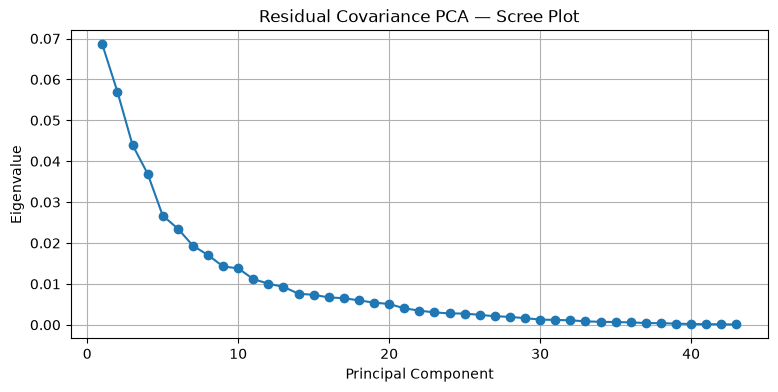

In [23]:
plt.figure(figsize=(9, 4))

plt.plot(
    range(1, n_stocks + 1),
    eigenvalues,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Residual Covariance PCA — Scree Plot")
plt.grid(True)
plt.show()

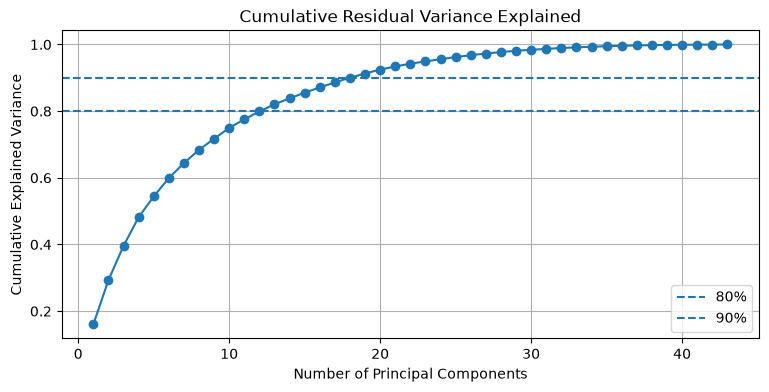

In [24]:
plt.figure(figsize=(9, 4))

plt.plot(
    range(1, n_stocks + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    0.80, linestyle="--", label="80%"
)

plt.axhline(
    0.90, linestyle="--", label="90%"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Residual Variance Explained")
plt.legend()
plt.grid(True)
plt.show()


In [25]:
df_residual_cov.to_excel(
    OUT / "equities_residual_cov_4w.xlsx",
    index_label="stock"
)

df_pca_summary.to_excel(
    OUT / "equities_residual_pca_summary.xlsx",
    index=False
)

df_eigenvectors.to_excel(
    OUT / "equities_residual_pca_eigenvectors.xlsx",
    index_label="stock"
)

df_pc_returns.to_excel(
    OUT / "equities_residual_pca_scores_4w.xlsx",
    index_label="date"
)